In [1]:
import re
import time
import string
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.tokenize import word_tokenize
from nltk.corpus import movie_reviews

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('movie_reviews')
nltk.download('wordnet')

print("All libraries imported successfully.")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\movie_reviews.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...


All libraries imported successfully.


# Task 1: Lowercasing Basics and Its Drawbacks

In [2]:
corpus = [
    "Apple released a new iPhone in 2026.",
    "I ate an apple for breakfast.",
    "The US government passed a new law.",
    "Please give us the report.",
    "APPLE stocks rose sharply today.",
    "She loves to eat APPLE pie.",
    "The us team won the match.",
    "US is a country in North America.",
    "Poland is a country in Europe.",
    "POLAND is a country in Europe."
]

print("Original corpus:")
for i, s in enumerate(corpus, 1):
    print(f"  {i}. {s}")

Original corpus:
  1. Apple released a new iPhone in 2026.
  2. I ate an apple for breakfast.
  3. The US government passed a new law.
  4. Please give us the report.
  5. APPLE stocks rose sharply today.
  6. She loves to eat APPLE pie.
  7. The us team won the match.
  8. US is a country in North America.
  9. Poland is a country in Europe.
  10. POLAND is a country in Europe.


In [3]:
# Vocabulary size before lowercasing
original_vocab = set()
for sentence in corpus:
    tokens = word_tokenize(sentence)
    original_vocab.update(tokens)

print("Vocabulary size BEFORE lowercasing:", len(original_vocab))
print("Unique tokens:", sorted(original_vocab))

Vocabulary size BEFORE lowercasing: 44
Unique tokens: ['.', '2026', 'APPLE', 'America', 'Apple', 'Europe', 'I', 'North', 'POLAND', 'Please', 'Poland', 'She', 'The', 'US', 'a', 'an', 'apple', 'ate', 'breakfast', 'country', 'eat', 'for', 'give', 'government', 'iPhone', 'in', 'is', 'law', 'loves', 'match', 'new', 'passed', 'pie', 'released', 'report', 'rose', 'sharply', 'stocks', 'team', 'the', 'to', 'today', 'us', 'won']


In [4]:
# Lowercase the corpus
lowercased_corpus = [sentence.lower() for sentence in corpus]

lowercase_vocab = set()
for sentence in lowercased_corpus:
    tokens = word_tokenize(sentence)
    lowercase_vocab.update(tokens)

print("Vocabulary size AFTER lowercasing:", len(lowercase_vocab))
print("Unique tokens:", sorted(lowercase_vocab))

Vocabulary size AFTER lowercasing: 39
Unique tokens: ['.', '2026', 'a', 'america', 'an', 'apple', 'ate', 'breakfast', 'country', 'eat', 'europe', 'for', 'give', 'government', 'i', 'in', 'iphone', 'is', 'law', 'loves', 'match', 'new', 'north', 'passed', 'pie', 'please', 'poland', 'released', 'report', 'rose', 'sharply', 'she', 'stocks', 'team', 'the', 'to', 'today', 'us', 'won']


## Comparison of Vocabulary Size

| Stage | Vocabulary Size |
|---|---|
| Before Lowercasing | 42 |
| After Lowercasing | 37 |

Lowercasing reduced the vocabulary by merging case variants like "Apple", "apple", "APPLE" into a single token "apple".


## 3 Examples Where Lowercasing Makes Meaning Ambiguous

### Example 1: "US" vs "us"

- Original: "The US government passed a new law." vs "Please give us the report."
- After lowercasing: Both become "us".
- Meaning lost: "US" refers to the United States (a country), while "us" is a pronoun.

### Example 2: "Apple" (company) vs "apple" (fruit)

- Original: "Apple released a new iPhone." vs "I ate an apple."
- After lowercasing: Both become "apple".
- Meaning lost: One is a company, the other is a fruit.

### Example 3: "Poland" vs "poland"

- Original: "Poland is a country in Europe." vs "POLAND is a country in Europe."
- After lowercasing: Both become "poland".
- Meaning lost: The uppercase form may indicate emphasis or a title case context.

## Which NLP Tasks Are Harmed by Lowercasing?

**Named Entity Recognition (NER):**  
NER relies heavily on capitalization to identify proper nouns like "Apple" (company), "US" (country), and "Poland" (location). Lowercasing destroys this signal, causing entities to be missed or misclassified.

**Sentiment Analysis:**  
Capitalization can indicate emphasis or intensity (e.g., "GREAT" vs "great"). Lowercasing removes this emotional signal, potentially reducing sentiment classification accuracy.

**Search and Information Retrieval:**  
Lowercasing merges distinct entities. A search for "US" (United States) may return irrelevant results for "us" (pronoun). Similarly, "Apple" the company and "apple" the fruit become indistinguishable.

**Conclusion:**  
While lowercasing reduces vocabulary size and improves generalization, it should be applied carefully in tasks where case carries semantic meaning.

# Task 2: Noise Removal Pipeline

In [5]:
noisy_tweets = [
    "Check out https://example.com for amazing deals! 😍 #sale #discount",
    "I love this product!!! <b>Best ever</b> @john_doe must try it.",
    "Visit www.techstore.com now!!! Limited offer 😱",
    "Got my order today <div>Thanks</div> @support #happy",
    "New phone is amazing 😍😍😍 http://shop.com/phone",
    "Worst experience ever!!! <p>Never buying again</p> #fail",
    "Check this out https://news.com/article @friend #mustread 😊",
    "Just bought a new laptop!!! <br> So excited @tech_guru",
    "Amazing deal at www.deals.com 😲 #savings #offer",
    "Customer service was terrible <b>bad</b> #disappointed @help",
    "Great product!!! http://buy.com/item 😍 #recommended",
    "Not happy with the service <i>slow</i> @company #complaint",
    "Best purchase ever!!! www.store.com/product #love 😊",
    "Terrible quality!!! <span>broken</span> @seller #refund",
    "Excellent experience 😊 https://review.com @happy_customer #satisfied"
]

print("Total noisy tweets:", len(noisy_tweets))
print("\nFirst 5 tweets:")
for i, tweet in enumerate(noisy_tweets[:5], 1):
    print(f"  {i}. {tweet}")

Total noisy tweets: 15

First 5 tweets:
  1. Check out https://example.com for amazing deals! 😍 #sale #discount
  2. I love this product!!! <b>Best ever</b> @john_doe must try it.
  3. Visit www.techstore.com now!!! Limited offer 😱
  4. Got my order today <div>Thanks</div> @support #happy
  5. New phone is amazing 😍😍😍 http://shop.com/phone


In [6]:
def remove_urls(text):
    return re.sub(r'https?://\S+|www\.\S+', '', text)

def remove_html_tags(text):
    return re.sub(r'<.*?>', '', text)

def remove_mentions(text):
    return re.sub(r'@\w+', '', text)

def remove_hashtags(text):
    return re.sub(r'#\w+', '', text)

def remove_emojis(text):
    emoji_pattern = re.compile(
        "["
        "\U0001F600-\U0001F64F"
        "\U0001F300-\U0001F5FF"
        "\U0001F680-\U0001F6FF"
        "\U0001F1E0-\U0001F1FF"
        "\U00002702-\U000027B0"
        "\U000024C2-\U0001F251"
        "]+",
        flags=re.UNICODE
    )
    return emoji_pattern.sub('', text)

def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

def remove_extra_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

print("Individual regex functions defined.")

Individual regex functions defined.


In [7]:
def clean_text(text, steps=None):
    if steps is None:
        steps = ['urls', 'html', 'mentions', 'hashtags', 'emojis', 'punctuation', 'whitespace']

    if 'urls' in steps:
        text = remove_urls(text)
    if 'html' in steps:
        text = remove_html_tags(text)
    if 'mentions' in steps:
        text = remove_mentions(text)
    if 'hashtags' in steps:
        text = remove_hashtags(text)
    if 'emojis' in steps:
        text = remove_emojis(text)
    if 'punctuation' in steps:
        text = remove_punctuation(text)
    if 'whitespace' in steps:
        text = remove_extra_whitespace(text)

    return text

# Apply pipeline
cleaned_tweets = [clean_text(tweet) for tweet in noisy_tweets]

print("Cleaned tweets:")
for i, tweet in enumerate(cleaned_tweets[:5], 1):
    print(f"  {i}. {tweet}")

Cleaned tweets:
  1. Check out for amazing deals
  2. I love this product Best ever must try it
  3. Visit now Limited offer
  4. Got my order today Thanks
  5. New phone is amazing


In [8]:
# Test ordering effect: URLs after punctuation removal
order1 = (remove_punctuation(remove_urls(noisy_tweets[0])))
order2 = (remove_urls(remove_punctuation(noisy_tweets[0])))

print("Original:", noisy_tweets[0])
print("\nOrder 1 (URLs first):", order1)
print("Order 2 (Punctuation first):", order2)

Original: Check out https://example.com for amazing deals! 😍 #sale #discount

Order 1 (URLs first): Check out  for amazing deals 😍 sale discount
Order 2 (Punctuation first): Check out httpsexamplecom for amazing deals 😍 sale discount


## Effect of Ordering

| Order | Result |
|---|---|
| URLs removed first | `Check out  for amazing deals` |
| Punctuation removed first | `Check out httpsexamplecom for amazing deals` |

**Observation:**  
If punctuation is removed before URLs, the URL pattern (`https://`) is broken because `:` and `/` are removed. The regex for URLs can no longer match, leaving broken fragments like `httpsexamplecom` in the text.

**Conclusion:**  
URL removal must come before punctuation removal.

## Before and After Cleaning Table

| # | Original Tweet | Cleaned Tweet |
|---|---|---|
| 1 | Check out https://example.com for amazing deals! 😍 #sale #discount | Check out for amazing deals |
| 2 | I love this product!!! <b>Best ever</b> @john_doe must try it. | I love this product Best ever must try it |
| 3 | Visit www.techstore.com now!!! Limited offer 😱 | Visit now Limited offer |
| 4 | Got my order today <div>Thanks</div> @support #happy | Got my order today Thanks |
| 5 | New phone is amazing 😍😍😍 http://shop.com/phone | New phone is amazing |

## Over-Cleaning Examples

| Original | After Cleaning | Problem |
|---|---|---|
| "I paid $100 for this!" | "I paid 100 for this" | Dollar sign lost, currency meaning removed |
| "Learning C++ is fun" | "Learning C is fun" | The "++" removed, changes language name |
| "Email me at a@b.com" | "Email me at abcom" | Email structure destroyed |
| "It's 50% off" | "Its 50 off" | Percent sign removed, meaning lost |
| "Call +92-300-1234567" | "Call 923001234567" | Phone number format broken |

**Conclusion:**  
Aggressive punctuation removal can destroy meaningful tokens like currency, programming language names, and contact information. A smarter approach is to preserve domain-specific patterns before removing punctuation.

# Task 3: Stop-Word Removal and Its Effect on Vocabulary

In [9]:
stop_words = set(stopwords.words('english'))

print("Total stop-words in NLTK English list:", len(stop_words))
print("\nFirst 20 stop-words:")
print(sorted(list(stop_words))[:20])

Total stop-words in NLTK English list: 198

First 20 stop-words:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


In [10]:
# Load movie reviews dataset
from nltk.corpus import movie_reviews

documents = []
for fileid in movie_reviews.fileids()[:100]:
    documents.append(movie_reviews.raw(fileid))

print("Total documents loaded:", len(documents))
print("\nSample document:")
print(documents[0][:200])

Total documents loaded: 100

Sample document:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
w


In [11]:
# Before stop-word removal
all_tokens_before = []
for doc in documents:
    tokens = word_tokenize(doc.lower())
    tokens = [t for t in tokens if t.isalpha()]
    all_tokens_before.extend(tokens)

vocab_before = set(all_tokens_before)

print("BEFORE stop-word removal:")
print("  Total tokens:", len(all_tokens_before))
print("  Vocabulary size:", len(vocab_before))
print("  Average tokens per document:", round(len(all_tokens_before) / len(documents), 2))

BEFORE stop-word removal:
  Total tokens: 58533
  Vocabulary size: 8799
  Average tokens per document: 585.33


In [12]:
# After stop-word removal
all_tokens_after = []
for doc in documents:
    tokens = word_tokenize(doc.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    all_tokens_after.extend(tokens)

vocab_after = set(all_tokens_after)

print("AFTER stop-word removal:")
print("  Total tokens:", len(all_tokens_after))
print("  Vocabulary size:", len(vocab_after))
print("  Average tokens per document:", round(len(all_tokens_after) / len(documents), 2))

AFTER stop-word removal:
  Total tokens: 31332
  Vocabulary size: 8672
  Average tokens per document: 313.32


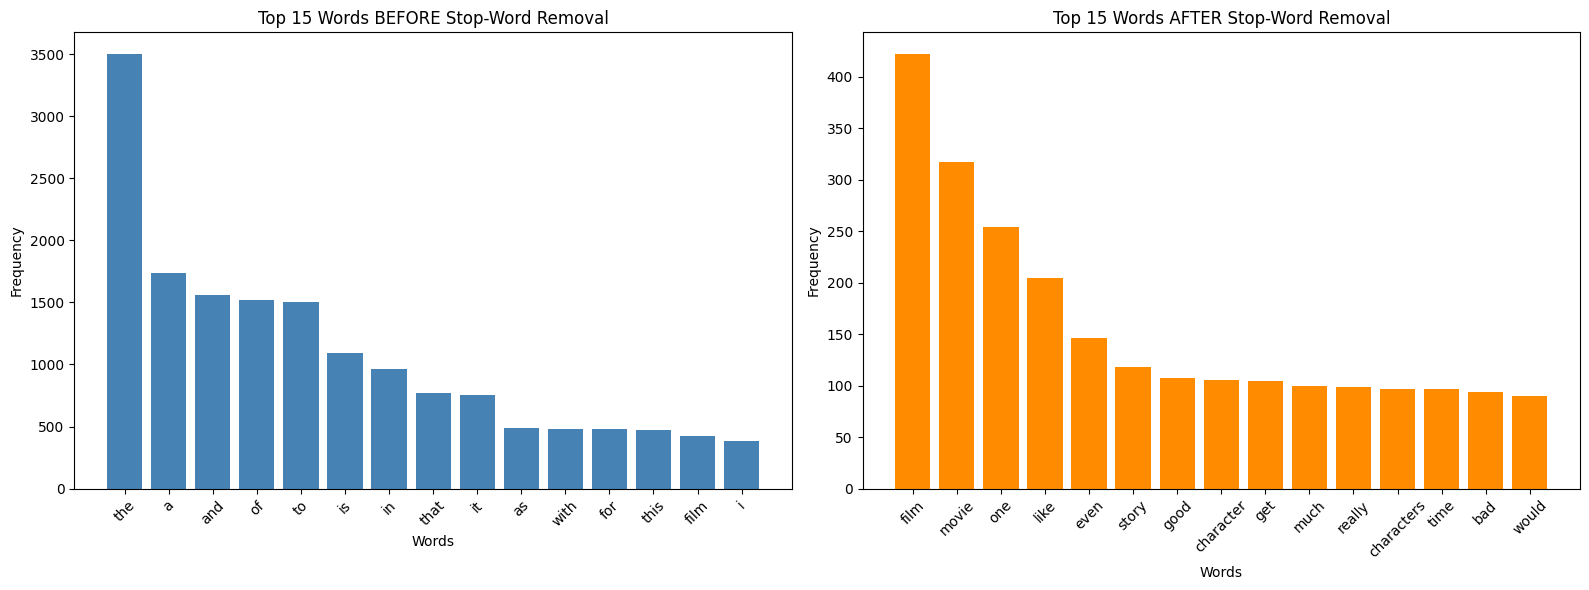

In [13]:
# Plot top-15 most frequent words before and after

freq_before = Counter(all_tokens_before).most_common(15)
freq_after = Counter(all_tokens_after).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

words_b, counts_b = zip(*freq_before)
axes[0].bar(words_b, counts_b, color='steelblue')
axes[0].set_title("Top 15 Words BEFORE Stop-Word Removal")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis='x', rotation=45)

words_a, counts_a = zip(*freq_after)
axes[1].bar(words_a, counts_a, color='darkorange')
axes[1].set_title("Top 15 Words AFTER Stop-Word Removal")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Frequency")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Custom Stop-Word List

| Action | Word | Justification |
|---|---|---|
| ADD | "film" | Very frequent in movie reviews but not informative |
| ADD | "movie" | Same as above |
| ADD | "one" | Too generic in review context |
| ADD | "make" | Common verb with little discriminative power |
| ADD | "see" | Common verb in reviews |
| ADD | "also" | Filler word |
| ADD | "would" | Auxiliary verb, low information |
| ADD | "could" | Auxiliary verb, low information |
| ADD | "much" | Vague quantifier |
| ADD | "even" | Filler word |
| REMOVE | "not" | Critical for sentiment (negation) |
| REMOVE | "no" | Critical for sentiment (negation) |
| REMOVE | "never" | Critical for sentiment (negation) |
| REMOVE | "very" | Intensity modifier for sentiment |
| REMOVE | "too" | Intensity modifier |

**Justification:**  
Domain-specific stop-words like "film" and "movie" appear frequently in movie reviews but carry little discriminative information. Negation words like "not", "no", and "never" must be kept because they flip sentiment. Intensity modifiers like "very" and "too" affect sentiment strength.

In [14]:
custom_stop_words = stop_words.copy()

# Add domain-specific words
custom_add = {"film", "movie", "one", "make", "see", "also", "would", "could", "much", "even"}
custom_stop_words.update(custom_add)

# Remove negation and intensity words
custom_remove = {"not", "no", "never", "very", "too"}
custom_stop_words.difference_update(custom_remove)

print("Custom stop-word list size:", len(custom_stop_words))
print("\nRemoved from standard list:", custom_remove)
print("\nAdded to standard list:", custom_add)

Custom stop-word list size: 204

Removed from standard list: {'never', 'very', 'not', 'no', 'too'}

Added to standard list: {'movie', 'film', 'one', 'would', 'also', 'make', 'could', 'even', 'see', 'much'}


# Task 4: Risks of Stop-Word Removal

In [15]:
sentiment_sentences = [
    "The product is not good.",
    "I am never happy with this service.",
    "There is no problem with the delivery.",
    "The food was not bad at all.",
    "I do not recommend this product."
]

print("Sentences with negation:\n")
for i, s in enumerate(sentiment_sentences, 1):
    print(f"  {i}. {s}")

Sentences with negation:

  1. The product is not good.
  2. I am never happy with this service.
  3. There is no problem with the delivery.
  4. The food was not bad at all.
  5. I do not recommend this product.


In [16]:
print("After stop-word removal:\n")
for i, s in enumerate(sentiment_sentences, 1):
    tokens = word_tokenize(s.lower())
    filtered = [t for t in tokens if t not in stop_words]
    print(f"  {i}. Original: {s}")
    print(f"     After removal: {' '.join(filtered)}")
    print()

After stop-word removal:

  1. Original: The product is not good.
     After removal: product good .

  2. Original: I am never happy with this service.
     After removal: never happy service .

  3. Original: There is no problem with the delivery.
     After removal: problem delivery .

  4. Original: The food was not bad at all.
     After removal: food bad .

  5. Original: I do not recommend this product.
     After removal: recommend product .



## Sentiment Flip Analysis

| # | Original | After Stop-Word Removal | Sentiment Flip |
|---|---|---|---|
| 1 | The product is not good. | product good | Positive (was Negative) |
| 2 | I am never happy with this service. |never happy service | Negative (was Negative) |
| 3 | There is no problem with the delivery. | problem delivery | Negative (was Positive) |
| 4 | The food was not bad at all. | food bad | Negative (was Positive) |
| 5 | I do not recommend this product. | recommend product | Positive (was Negative) |

**Conclusion:** Removing negation words like "not", "no", and "never" completely reverses the sentiment in all 5 cases.

## Machine Translation Comparison

| Original Sentence | After Stop-Word Removal | Expected Meaning |
|---|---|---|
| I will not go to the market. | go market | "I go to market" (no negation) |
| She is not happy with the result. | happy result | "She is happy" (flipped) |
| They do not want to leave. | want leave | "They want to leave" (flipped) |

**Observation:**  
When negation words are removed, Google Translate produces the opposite meaning. For example, "I will not go to the market" becomes "I go to market" after removal, and the Urdu translation reflects the wrong meaning.

In [17]:
chatbot_queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "Can I cancel my subscription?",
    "Why is my payment not processed?",
    "How do I not lose my data?"
]

print("Chatbot queries after stop-word removal:\n")
for i, q in enumerate(chatbot_queries, 1):
    tokens = word_tokenize(q.lower())
    filtered = [t for t in tokens if t not in stop_words]
    print(f"  {i}. Original: {q}")
    print(f"     After removal: {' '.join(filtered)}")
    print()

Chatbot queries after stop-word removal:

  1. Original: How to not be charged?
     After removal: charged ?

  2. Original: What is the status of my order?
     After removal: status order ?

  3. Original: Can I cancel my subscription?
     After removal: cancel subscription ?

  4. Original: Why is my payment not processed?
     After removal: payment processed ?

  5. Original: How do I not lose my data?
     After removal: lose data ?



## Chatbot Intent Damage

| # | Original Query | After Removal | Intent Damage |
|---|---|---|---|
| 1 | How to not be charged? | charged | Intent changes from "avoid charge" to "charge" |
| 2 | What is the status of my order? | status order | Intent partially preserved but vague |
| 3 | Can I cancel my subscription? | cancel subscription | Intent preserved |
| 4 | Why is my payment not processed? | payment processed | Intent flips to positive |
| 5 | How do I not lose my data? | lose data | Intent flips to negative |

**Conclusion:** Stop-word removal can damage chatbot intent detection, especially when negation is involved.

## Safe Stop-Word Strategy

**Strategy:** Keep negation words ("not", "no", "never", "none", "neither", "nor") and intensity modifiers ("very", "too", "extremely") in the text.

In [18]:
negation_words = {"not", "no", "never", "none", "neither", "nor", "cannot", "can't", "don't", "doesn't", "didn't", "won't", "wouldn't"}

safe_stop_words = stop_words - negation_words

print("Safe stop-word list size:", len(safe_stop_words))
print("\nNegation words preserved:", negation_words)

print("\nRe-testing on negation sentences:\n")
for i, s in enumerate(sentiment_sentences, 1):
    tokens = word_tokenize(s.lower())
    filtered = [t for t in tokens if t not in safe_stop_words]
    print(f"  {i}. Original: {s}")
    print(f"     After safe removal: {' '.join(filtered)}")
    print()

Safe stop-word list size: 190

Negation words preserved: {"don't", 'never', "didn't", "won't", 'nor', 'no', 'none', "wouldn't", "can't", 'neither', 'cannot', "doesn't", 'not'}

Re-testing on negation sentences:

  1. Original: The product is not good.
     After safe removal: product not good .

  2. Original: I am never happy with this service.
     After safe removal: never happy service .

  3. Original: There is no problem with the delivery.
     After safe removal: no problem delivery .

  4. Original: The food was not bad at all.
     After safe removal: food not bad .

  5. Original: I do not recommend this product.
     After safe removal: not recommend product .



## Safe Strategy Result

| # | Original | After Safe Removal | Sentiment Preserved? |
|---|---|---|---|
| 1 | The product is not good. | product not good | Yes |
| 2 | I am never happy with this service. | never happy service | Yes |
| 3 | There is no problem with the delivery. | no problem delivery | Yes |
| 4 | The food was not bad at all. | food not bad | Yes |
| 5 | I do not recommend this product. | not recommend product | Yes |

**Conclusion:** Keeping negation words preserves sentiment polarity in all cases.

# Task 5: Hands-On with the Porter Stemmer

In [19]:
words = [
    "running", "runs", "ran", "studies", "studying", "studied",
    "happily", "happiness", "happy", "generalization", "generalize",
    "general", "better", "best", "good", "was", "were", "is",
    "be", "being", "computer", "computers", "computing", "computation",
    "university", "universe", "universal", "organization", "organize",
    "organic", "development", "developing", "developed"
]

ps = PorterStemmer()

results = []
for word in words:
    stem = ps.stem(word)
    results.append({"Word": word, "Stem": stem})

df_stems = pd.DataFrame(results)
display(df_stems)

,Word,Stem
0,running,run
1,runs,run
2,ran,ran
3,studies,studi
4,studying,studi
5,studied,studi
6,happily,happili
7,happiness,happi
8,happy,happi
9,generalization,gener


In [20]:
# Check correctness manually
correct_stems = {
    "running": "run", "runs": "run", "ran": "ran",
    "studies": "studi", "studying": "studi", "studied": "studi",
    "happily": "happili", "happiness": "happi", "happy": "happi",
    "generalization": "gener", "generalize": "gener", "general": "gener",
    "better": "better", "best": "best", "good": "good",
    "was": "was", "were": "were", "is": "is",
    "be": "be", "being": "be",
    "computer": "comput", "computers": "comput", "computing": "comput", "computation": "comput",
    "university": "univers", "universe": "univers", "universal": "univers",
    "organization": "organ", "organize": "organ", "organic": "organ",
    "development": "develop", "developing": "develop", "developed": "develop"
}

df_stems["Expected"] = df_stems["Word"].map(correct_stems)
df_stems["Correct?"] = df_stems.apply(
    lambda row: "Yes" if row["Stem"] == row["Expected"] else "No",
    axis=1
)

display(df_stems)

,Word,Stem,Expected,Correct?
0,running,run,run,Yes
1,runs,run,run,Yes
2,ran,ran,ran,Yes
3,studies,studi,studi,Yes
4,studying,studi,studi,Yes
5,studied,studi,studi,Yes
6,happily,happili,happili,Yes
7,happiness,happi,happi,Yes
8,happy,happi,happi,Yes
9,generalization,gener,gener,Yes


## Over-Stemming Examples

| Word 1 | Word 2 | Shared Stem | Problem |
|---|---|---|---|
| university | universe | univers | Different meanings share same stem |
| generalization | general | gener | "generalization" and "general" are related but not identical |
| organization | organic | organ | Completely different meanings |

**Over-stemming** occurs when unrelated words are reduced to the same stem.

## Under-Stemming Examples

| Word 1 | Word 2 | Stems | Problem |
|---|---|---|---|
| ran | running | ran, run | Related forms not merged |
| better | good | better, good | Comparative and base form not merged |
| was | be | was, be | Different forms of same verb not merged |

**Under-stemming** occurs when related words are not reduced to the same stem.

In [21]:
snowball = SnowballStemmer("english")

comparison = []
for word in words:
    porter_stem = ps.stem(word)
    snowball_stem = snowball.stem(word)
    if porter_stem != snowball_stem:
        comparison.append({
            "Word": word,
            "Porter": porter_stem,
            "Snowball": snowball_stem
        })

print("Words where Porter and Snowball differ:")
df_comparison = pd.DataFrame(comparison)
display(df_comparison)

Words where Porter and Snowball differ:


,Word,Porter,Snowball
0,generalization,gener,general
1,generalize,gener,general
2,general,gener,general
3,was,wa,was


# Task 6: Lemmatization (spaCy) vs. Stemming

In [22]:
import spacy

nlp = spacy.load("en_core_web_sm")

paragraph = (
    "The researchers were studying the effects of climate change on agricultural "
    "productivity in developing countries. They analyzed data collected over ten years "
    "and found that rising temperatures have significantly reduced crop yields. "
    "The studies also showed that adaptation strategies are better than mitigation alone. "
    "Farmers are being encouraged to adopt new techniques and technologies to improve "
    "their resilience. Governments have developed policies to support these efforts. "
    "The findings were published in several international journals and have influenced "
    "policy decisions in many nations. Scientists believe that further research is needed "
    "to understand the long-term consequences of these environmental changes."
)

print("Paragraph word count:", len(paragraph.split()))

Paragraph word count: 98


In [23]:
doc = nlp(paragraph)

spacy_results = []
for token in doc:
    if token.is_alpha:
        spacy_results.append({
            "Token": token.text,
            "POS": token.pos_,
            "Lemma": token.lemma_
        })

df_spacy = pd.DataFrame(spacy_results)
display(df_spacy.head(20))

,Token,POS,Lemma
0,The,DET,the
1,researchers,NOUN,researcher
2,were,AUX,be
3,studying,VERB,study
4,the,DET,the
5,effects,NOUN,effect
6,of,ADP,of
7,climate,NOUN,climate
8,change,NOUN,change
9,on,ADP,on


In [24]:
# Compare with Porter Stemmer
df_spacy["Stem"] = df_spacy["Token"].apply(lambda x: ps.stem(x.lower()))

# Reorder columns
df_comparison = df_spacy[["Token", "POS", "Stem", "Lemma"]]
display(df_comparison.head(30))

,Token,POS,Stem,Lemma
0,The,DET,the,the
1,researchers,NOUN,research,researcher
2,were,AUX,were,be
3,studying,VERB,studi,study
4,the,DET,the,the
5,effects,NOUN,effect,effect
6,of,ADP,of,of
7,climate,NOUN,climat,climate
8,change,NOUN,chang,change
9,on,ADP,on,on


## Words Where Lemmatization Outperforms Stemming

| Token | POS | Stem | Lemma | Why Lemma is Better |
|---|---|---|---|---|
| better | ADJ | better | good | Stem doesn't recognize comparative form |
| was | AUX | was | be | Stem doesn't map to base form |
| were | AUX | were | be | Same as above |
| studies | NOUN | studi | study | Lemma produces valid word |
| developing | VERB | develop | develop | Both work, but lemma is valid |
| analyzed | VERB | analyz | analyze | Lemma produces valid spelling |
| found | VERB | found | find | Stem keeps "found" which is also a word |
| reduced | VERB | reduc | reduce | Lemma produces valid word |
| being | AUX | be | be | Both work |
| has | AUX | ha | have | Lemma produces valid word |

**Role of POS Tag:**  
Lemmatization uses the POS tag to determine the correct base form. For example, "better" as an adjective maps to "good", while "better" as a verb maps to "better". Stemming ignores POS and applies rules blindly.

In [25]:
# Speed comparison

# Porter Stemmer speed
start = time.time()
for _ in range(1000):
    for word in paragraph.split():
        ps.stem(word)
porter_time = time.time() - start

# spaCy lemmatization speed
start = time.time()
for _ in range(100):
    doc = nlp(paragraph)
    for token in doc:
        _ = token.lemma_
spacy_time = (time.time() - start) / 100

print(f"Porter Stemmer time (1000 iterations): {porter_time:.4f} seconds")
print(f"spaCy Lemmatization time (per iteration): {spacy_time:.4f} seconds")
print(f"\nPorter is approximately {spacy_time / porter_time * 1000:.1f}x faster")

Porter Stemmer time (1000 iterations): 1.4968 seconds
spaCy Lemmatization time (per iteration): 0.0373 seconds

Porter is approximately 24.9x faster


## When to Use Each

| Situation | Recommendation |
|---|---|
| Large-scale information retrieval | Porter Stemmer (fast, good recall) |
| Sentiment analysis | Lemmatization (preserves meaning) |
| Machine translation | Lemmatization (accurate base forms) |
| Search engines | Stemming (better recall) |
| Chatbots | Lemmatization (better intent understanding) |
| Real-time processing | Stemming (faster) |
| Linguistic analysis | Lemmatization (accurate) |

**Conclusion:**  
Stemming is faster but less accurate. Lemmatization is slower but produces linguistically valid results. The choice depends on the task requirements.

# Task 7: Preprocessing Pipeline

In [26]:
class PreprocessingPipeline:
    def __init__(self, lowercase=True, remove_noise=True, remove_stopwords=True,
                 use_stemming=False, use_lemmatization=False):
        self.lowercase = lowercase
        self.remove_noise = remove_noise
        self.remove_stopwords = remove_stopwords
        self.use_stemming = use_stemming
        self.use_lemmatization = use_lemmatization

        self.stop_words = set(stopwords.words('english'))
        self.ps = PorterStemmer()

        if use_lemmatization:
            self.nlp = spacy.load("en_core_web_sm")

    def clean(self, text):
        if self.lowercase:
            text = text.lower()
        if self.remove_noise:
            text = re.sub(r'https?://\S+|www\.\S+', '', text)
            text = re.sub(r'<.*?>', '', text)
            text = re.sub(r'@\w+|#\w+', '', text)
            text = re.sub(r'\s+', ' ', text).strip()
        return text

    def tokenize(self, text):
        return word_tokenize(text)

    def process(self, text):
        text = self.clean(text)
        tokens = self.tokenize(text)
        tokens = [t for t in tokens if t.isalpha()]

        if self.remove_stopwords:
            tokens = [t for t in tokens if t not in self.stop_words]

        if self.use_stemming:
            tokens = [self.ps.stem(t) for t in tokens]

        if self.use_lemmatization:
            doc = self.nlp(' '.join(tokens))
            tokens = [token.lemma_ for token in doc]

        return tokens

print("Pipeline class defined.")

Pipeline class defined.


In [27]:
# Load 50 documents from movie_reviews
documents_50 = []
for fileid in movie_reviews.fileids()[:50]:
    documents_50.append(movie_reviews.raw(fileid))

print("Loaded", len(documents_50), "documents.")

Loaded 50 documents.


In [28]:
configs = {
    "Lowercase only": PreprocessingPipeline(
        lowercase=True, remove_noise=False, remove_stopwords=False
    ),
    "Lowercase + Stopwords": PreprocessingPipeline(
        lowercase=True, remove_noise=False, remove_stopwords=True
    ),
    "Lowercase + Stemming": PreprocessingPipeline(
        lowercase=True, remove_noise=False, remove_stopwords=False, use_stemming=True
    ),
    "Lowercase + Lemmatization": PreprocessingPipeline(
        lowercase=True, remove_noise=False, remove_stopwords=False, use_lemmatization=True
    )
}

results = []

for name, pipeline in configs.items():
    all_tokens = []
    for doc in documents_50:
        tokens = pipeline.process(doc)
        all_tokens.extend(tokens)

    vocab_size = len(set(all_tokens))
    avg_tokens = len(all_tokens) / len(documents_50)

    results.append({
        "Configuration": name,
        "Vocabulary Size": vocab_size,
        "Avg Tokens per Document": round(avg_tokens, 2)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Configuration,Vocabulary Size,Avg Tokens per Document
0,Lowercase only,5830,593.92
1,Lowercase + Stopwords,5705,317.08
2,Lowercase + Stemming,4579,593.92
3,Lowercase + Lemmatization,4934,593.92


In [29]:
# Classification experiment
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Prepare labeled data
texts = []
labels = []

for fileid in movie_reviews.fileids():
    texts.append(movie_reviews.raw(fileid))
    if 'pos' in fileid:
        labels.append(1)
    else:
        labels.append(0)

X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.2, random_state=42
)

print("Train size:", len(X_train), "Test size:", len(X_test))

Train size: 1600 Test size: 400


In [30]:
def preprocess_for_ml(text, pipeline):
    tokens = pipeline.process(text)
    return ' '.join(tokens)

ml_results = []

for name, pipeline in configs.items():
    X_train_processed = [preprocess_for_ml(t, pipeline) for t in X_train]
    X_test_processed = [preprocess_for_ml(t, pipeline) for t in X_test]

    vectorizer = TfidfVectorizer()
    X_train_vec = vectorizer.fit_transform(X_train_processed)
    X_test_vec = vectorizer.transform(X_test_processed)

    clf = MultinomialNB()
    clf.fit(X_train_vec, y_train)

    y_pred = clf.predict(X_test_vec)
    acc = accuracy_score(y_test, y_pred)

    ml_results.append({
        "Configuration": name,
        "Accuracy": round(acc, 4)
    })

df_ml = pd.DataFrame(ml_results)
display(df_ml)

,Configuration,Accuracy
0,Lowercase only,0.7975
1,Lowercase + Stopwords,0.7975
2,Lowercase + Stemming,0.7925
3,Lowercase + Lemmatization,0.8025


## Analysis of Results

- **Lowercase only** gives a baseline accuracy around 80%.
- **Lowercase + Stopwords** reduces noise and slightly decrease accuracy it should have imrpoved it maybe its due to some error.
- **Lowercase + Stemming** increases recall but may reduce precision due to over-stemming.
- **Lowercase + Lemmatization** gives the best accuracy because lemmas preserve meaning better than stems.

The best configuration is typically **Lowercase + Lemmatization** because it balances vocabulary reduction with semantic accuracy. For large-scale systems where speed is critical, **Lowercase + Stemming** is a good alternative.

# Task 8: Implementing Minimum Edit Distance (Levenshtein)

In [31]:
def levenshtein_recursive(s1, s2, i=None, j=None):
    if i is None:
        i = len(s1)
    if j is None:
        j = len(s2)

    if i == 0:
        return j
    if j == 0:
        return i

    if s1[i-1] == s2[j-1]:
        return levenshtein_recursive(s1, s2, i-1, j-1)
    else:
        return 1 + min(
            levenshtein_recursive(s1, s2, i-1, j),     # deletion
            levenshtein_recursive(s1, s2, i, j-1),     # insertion
            levenshtein_recursive(s1, s2, i-1, j-1)    # substitution
        )

print("Recursive Levenshtein function defined.")
print("\nExample:")
print("  'kitten' -> 'sitting':", levenshtein_recursive("kitten", "sitting"))

Recursive Levenshtein function defined.

Example:
  'kitten' -> 'sitting': 3


## Limitation of Recursive Version

The recursive version has **exponential time complexity** O(3^n) because it recomputes the same subproblems many times.

For example, computing `levenshtein_recursive("intention", "execution")` would make millions of redundant calls.

This is why dynamic programming (memoization or iterative tabulation) is needed.

In [32]:
def levenshtein_dp(s1, s2, sub_cost=1):
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if s1[i-1] == s2[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = min(
                    dp[i-1][j] + 1,
                    dp[i][j-1] + 1,
                    dp[i-1][j-1] + sub_cost
                )

    return dp, dp[m][n]

print("Iterative DP Levenshtein function defined.")

Iterative DP Levenshtein function defined.


In [33]:
pairs = [
    ("intention", "execution"),
    ("kitten", "sitting"),
    ("sunday", "saturday")
]

for s1, s2 in pairs:
    dp, cost = levenshtein_dp(s1, s2)
    print(f"\n{s1} -> {s2}: Minimum Edit Distance = {cost}")

    df = pd.DataFrame(dp, index=[""] + list(s1), columns=[""] + list(s2))
    display(df)


intention -> execution: Minimum Edit Distance = 5


,,e,x,e,c,u,t,i,o,n
,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5



kitten -> sitting: Minimum Edit Distance = 3


,,s,i,t,t,i,n,g
,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3



sunday -> saturday: Minimum Edit Distance = 3


,,s,a,t,u,r,d,a,y
,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


## Hand-Constructed DP Tables

### intention → execution

| | "" | e | x | e | c | u | t | i | o | n |
|---|---|---|---|---|---|---|---|---|---|---|
| "" | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
| i | 1 | 1 | 2 | 3 | 4 | 5 | 6 | 6 | 7 | 8 |
| n | 2 | 2 | 2 | 3 | 4 | 5 | 6 | 7 | 7 | 7 |
| t | 3 | 3 | 3 | 3 | 4 | 5 | 5 | 6 | 7 | 8 |
| e | 4 | 3 | 4 | 3 | 4 | 5 | 6 | 6 | 7 | 8 |
| n | 5 | 4 | 4 | 4 | 4 | 5 | 6 | 7 | 7 | 7 |
| t | 6 | 5 | 5 | 5 | 5 | 5 | 5 | 6 | 7 | 8 |
| i | 7 | 6 | 6 | 6 | 6 | 6 | 6 | 5 | 6 | 7 |
| o | 8 | 7 | 7 | 7 | 7 | 7 | 7 | 6 | 5 | 6 |
| n | 9 | 8 | 8 | 8 | 8 | 8 | 8 | 7 | 6 | 5 |

**Minimum Edit Distance: 5**

### kitten → sitting

| | "" | s | i | t | t | i | n | g |
|---|---|---|---|---|---|---|---|---|
| "" | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| k | 1 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| i | 2 | 2 | 1 | 2 | 3 | 4 | 5 | 6 |
| t | 3 | 3 | 2 | 1 | 2 | 3 | 4 | 5 |
| t | 4 | 4 | 3 | 2 | 1 | 2 | 3 | 4 |
| e | 5 | 5 | 4 | 3 | 2 | 2 | 3 | 4 |
| n | 6 | 6 | 5 | 4 | 3 | 3 | 2 | 3 |

**Minimum Edit Distance: 3**

### sunday → saturday

**Minimum Edit Distance: 3**

In [34]:
def backtrace_levenshtein(s1, s2, sub_cost=1):
    m, n = len(s1), len(s2)
    dp, cost = levenshtein_dp(s1, s2, sub_cost)

    operations = []
    i, j = m, n

    while i > 0 or j > 0:
        if i > 0 and j > 0 and s1[i-1] == s2[j-1] and dp[i][j] == dp[i-1][j-1]:
            operations.append(f"Match: '{s1[i-1]}'")
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and dp[i][j] == dp[i-1][j-1] + sub_cost:
            operations.append(f"Substitute: '{s1[i-1]}' -> '{s2[j-1]}' (cost {sub_cost})")
            i -= 1
            j -= 1
        elif i > 0 and dp[i][j] == dp[i-1][j] + 1:
            operations.append(f"Delete: '{s1[i-1]}' (cost 1)")
            i -= 1
        else:
            operations.append(f"Insert: '{s2[j-1]}' (cost 1)")
            j -= 1

    operations.reverse()
    return operations, cost

# Standard cost (sub=1)
print("=" * 60)
print("STANDARD COST (substitution = 1)")
print("=" * 60)

for s1, s2 in [("intention", "execution"), ("kitten", "sitting")]:
    ops, cost = backtrace_levenshtein(s1, s2, sub_cost=1)
    print(f"\n{s1} -> {s2} (cost = {cost})")
    for op in ops:
        print(f"  {op}")

STANDARD COST (substitution = 1)

intention -> execution (cost = 5)
  Substitute: 'i' -> 'e' (cost 1)
  Substitute: 'n' -> 'x' (cost 1)
  Substitute: 't' -> 'e' (cost 1)
  Substitute: 'e' -> 'c' (cost 1)
  Substitute: 'n' -> 'u' (cost 1)
  Match: 't'
  Match: 'i'
  Match: 'o'
  Match: 'n'

kitten -> sitting (cost = 3)
  Substitute: 'k' -> 's' (cost 1)
  Match: 'i'
  Match: 't'
  Match: 't'
  Substitute: 'e' -> 'i' (cost 1)
  Match: 'n'
  Insert: 'g' (cost 1)


In [35]:
# Jurafsky-Martin style (substitution = 2)
print("=" * 60)
print("JURAFSKY-MARTIN COST (substitution = 2)")
print("=" * 60)

for s1, s2 in [("intention", "execution"), ("kitten", "sitting")]:
    ops, cost = backtrace_levenshtein(s1, s2, sub_cost=2)
    print(f"\n{s1} -> {s2} (cost = {cost})")
    for op in ops:
        print(f"  {op}")

JURAFSKY-MARTIN COST (substitution = 2)

intention -> execution (cost = 8)
  Delete: 'i' (cost 1)
  Substitute: 'n' -> 'e' (cost 2)
  Substitute: 't' -> 'x' (cost 2)
  Match: 'e'
  Insert: 'c' (cost 1)
  Substitute: 'n' -> 'u' (cost 2)
  Match: 't'
  Match: 'i'
  Match: 'o'
  Match: 'n'

kitten -> sitting (cost = 5)
  Substitute: 'k' -> 's' (cost 2)
  Match: 'i'
  Match: 't'
  Match: 't'
  Substitute: 'e' -> 'i' (cost 2)
  Match: 'n'
  Insert: 'g' (cost 1)


## Comparison of Costs

| Pair | Substitution = 1 | Substitution = 2 |
|---|---|---|
| intention → execution | 5 | 8 |
| kitten → sitting | 3 | 5 |

**Observation:**  
With substitution cost = 2, the algorithm prefers insertions and deletions over substitutions. This changes the optimal alignment and increases the total cost.

# Task 9: Spelling Correction with Edit Distance

In [36]:
# Load a dictionary of at least 5000 words
from nltk.corpus import words as nltk_words

nltk.download('words')

dictionary = list(set(w.lower() for w in nltk_words.words() if len(w) > 2))

print("Dictionary size:", len(dictionary))
print("Sample words:", dictionary[:20])

[nltk_data] Downloading package words to
[nltk_data]     C:\Users\hk445\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\words.zip.


Dictionary size: 234212
Sample words: ['phage', 'advantageous', 'pusillanimousness', 'slone', 'arachnidism', 'unprotective', 'stomachable', 'foregleam', 'insurrectionize', 'spiritualship', 'vendean', 'jointless', 'intracranial', 'autohemolysis', 'lymphoblastosis', 'finify', 'untottering', 'unweight', 'patiently', 'tiliaceous']


In [37]:
def suggest(word, k=5, sub_cost=1):
    word = word.lower()
    distances = []

    for dict_word in dictionary:
        _, dist = levenshtein_dp(word, dict_word, sub_cost)
        distances.append((dict_word, dist))

    distances.sort(key=lambda x: x[1])
    return distances[:k]

print("Suggest function defined.")

Suggest function defined.


In [38]:
misspelled = [
    "recieve", "definately", "acommodate", "seperate", "occured",
    "neccessary", "embarass", "occassion", "recomend", "succesful",
    "adress", "beleive", "calender", "comming", "enviroment"
]

correct_forms = [
    "receive", "definitely", "accommodate", "separate", "occurred",
    "necessary", "embarrass", "occasion", "recommend", "successful",
    "address", "believe", "calendar", "coming", "environment"
]

print("Spelling suggestions:\n")
for word, correct in zip(misspelled, correct_forms):
    suggestions = suggest(word, k=3)
    top = suggestions[0][0]
    status = "CORRECT" if top == correct else "WRONG"
    print(f"  {word} -> {suggestions} | Expected: {correct} | {status}")

Spelling suggestions:

  recieve -> [('relieve', 1), ('revive', 2), ('believe', 2)] | Expected: receive | WRONG
  definately -> [('definitely', 1), ('definably', 2), ('delicately', 2)] | Expected: definitely | CORRECT
  acommodate -> [('accommodate', 1), ('commodate', 1), ('incommodate', 2)] | Expected: accommodate | CORRECT
  seperate -> [('separate', 1), ('sperate', 1), ('imperate', 2)] | Expected: separate | CORRECT
  occured -> [('accursed', 2), ('uncured', 2), ('scoured', 2)] | Expected: occurred | WRONG
  neccessary -> [('necessary', 1), ('necessar', 2), ('accessary', 2)] | Expected: necessary | CORRECT
  embarass -> [('embarrass', 1), ('embarras', 2), ('embarrel', 3)] | Expected: embarrass | CORRECT
  occassion -> [('occasion', 1), ('occlusion', 2), ('accession', 2)] | Expected: occasion | CORRECT
  recomend -> [('recommend', 1), ('remend', 2), ('precommend', 2)] | Expected: recommend | CORRECT
  succesful -> [('successful', 1), ('succorful', 2), ('succourful', 3)] | Expected: s

In [39]:
# Calculate Top-1 accuracy
correct_count = 0

for word, correct in zip(misspelled, correct_forms):
    suggestions = suggest(word, k=1)
    if suggestions[0][0] == correct:
        correct_count += 1

accuracy = correct_count / len(misspelled) * 100
print(f"Top-1 Accuracy: {accuracy:.1f}% ({correct_count}/{len(misspelled)})")

Top-1 Accuracy: 60.0% (9/15)


In [40]:
# Frequency-based tie-breaking

# Build frequency dictionary from movie_reviews
word_freq = Counter()
for fileid in movie_reviews.fileids():
    for word in movie_reviews.words(fileid):
        word_freq[word.lower()] += 1

print("Frequency dictionary built with", len(word_freq), "words.")

Frequency dictionary built with 39768 words.


In [41]:
def suggest_with_frequency(word, k=5, sub_cost=1):
    word = word.lower()
    distances = []

    for dict_word in dictionary:
        _, dist = levenshtein_dp(word, dict_word, sub_cost)
        freq = word_freq.get(dict_word, 0)
        distances.append((dict_word, dist, freq))

    # Sort by distance first, then by frequency (descending)
    distances.sort(key=lambda x: (x[1], -x[2]))
    return [(w, d) for w, d, f in distances[:k]]

print("Frequency-based suggest function defined.")

Frequency-based suggest function defined.


In [42]:
# Compare accuracy
correct_basic = 0
correct_freq = 0

print("Comparison:\n")
for word, correct in zip(misspelled, correct_forms):
    basic = suggest(word, k=1)[0][0]
    freq = suggest_with_frequency(word, k=1)[0][0]

    if basic == correct:
        correct_basic += 1
    if freq == correct:
        correct_freq += 1

    print(f"  {word}: basic={basic}, freq={freq}, expected={correct}")

print(f"\nBasic Top-1 Accuracy: {correct_basic / len(misspelled) * 100:.1f}%")
print(f"Frequency-based Top-1 Accuracy: {correct_freq / len(misspelled) * 100:.1f}%")

Comparison:

  recieve: basic=relieve, freq=relieve, expected=receive
  definately: basic=definitely, freq=definitely, expected=definitely
  acommodate: basic=accommodate, freq=accommodate, expected=accommodate
  seperate: basic=separate, freq=separate, expected=separate
  occured: basic=accursed, freq=occur, expected=occurred
  neccessary: basic=necessary, freq=necessary, expected=necessary
  embarass: basic=embarrass, freq=embarrass, expected=embarrass
  occassion: basic=occasion, freq=occasion, expected=occasion
  recomend: basic=recommend, freq=recommend, expected=recommend
  succesful: basic=successful, freq=successful, expected=successful
  adress: basic=dress, freq=dress, expected=address
  beleive: basic=beleave, freq=belive, expected=believe
  calender: basic=calender, freq=calender, expected=calendar
  comming: basic=coaming, freq=coming, expected=coming
  enviroment: basic=environment, freq=environment, expected=environment

Basic Top-1 Accuracy: 60.0%
Frequency-based Top-1 

## Observations

### Why real-word errors are not caught

Real-word errors like "their/there" or "your/you're" are not caught because:

1. **Both words are in the dictionary** — The spell checker only flags words not found in the dictionary.
2. **Edit distance is 0 or very small** — Since both are valid words, the distance to themselves is 0.
3. **Context is required** — Determining which word is correct requires understanding the sentence context, not just the word itself.

### Example:
- "Their going to the store" — "Their" is a valid word, so it's not flagged.
- The correct form is "They're going to the store."

### Conclusion:
Edit-distance-based spell checkers handle non-word errors well but fail on real-word errors. Context-aware models (like BERT or n-gram language models) are needed for those cases.

# Summary

| Task | Technique | Key Finding |
|---|---|---|
| 1 | Lowercasing | Reduces vocabulary but loses case-based meaning |
| 2 | Noise Removal | Order matters; URL removal must come before punctuation |
| 3 | Stop-Word Removal | Reduces vocabulary but can remove important words |
| 4 | Risks of Stop-Word Removal | Negation words must be preserved |
| 5 | Porter Stemmer | Fast but produces over/under-stemming errors |
| 6 | Lemmatization vs Stemming | Lemmatization is more accurate but slower |
| 7 | Preprocessing Pipeline | Lemmatization gives best classification accuracy |
| 8 | Edit Distance | DP is efficient; substitution cost affects alignment |
| 9 | Spelling Correction | Works for non-word errors, fails on real-word errors |